# 12 — Direct Cífka CLP compression validation

This notebook stress-tests the context-curve compression result against the released
`cifkao/context-probing` implementation from Cífka & Liutkus (ACL 2023).

The experiment has four goals:

1. **Toolkit equivalence audit.** Verify that the released context-probing machinery
   produces the same \(L_k\) values as direct truncated-context scoring at selected
   targets.
2. **Dense CLP compression.** Replace our four sampled windows by the dense toolkit
   curve
   \[
   C_{\mathrm{CLP}}=(L_8,L_9,\ldots,L_{256})
   \]
   and test how much source-attribution performance survives compression.
3. **Classical curve approximations.** Compare linear and log-linear
   interpolation/fits against the observed dense curve.
4. **Attribution from low-dimensional fits.** Compare the two fitted coefficients
   of linear/log-linear models against two endpoints, one endpoint, and the dense
   CLP curve.

The central compression question is

\[
\operatorname{Perf}(L_{256})
\stackrel{?}{\approx}
\operatorname{Perf}(L_8,\ldots,L_{256}).
\]

This is intentionally stronger than notebook 11, which compressed only a four-point
sample of the curve.


## Important implementation note

The notebook imports the **released `context-probing` package** and uses its
windowing/diagonalization/NLL machinery directly.

Some releases of the package contain an `xent`-only fast-path incompatibility:
`run_probing()` removes `labels` before `get_logprobs(..., labels_only=True)` later
expects them. The notebook therefore:

1. first smoke-tests the official `run_probing(..., metrics=["xent"])`;
2. uses it unchanged if it works;
3. otherwise activates a minimal compatibility adapter that preserves the toolkit's
   `get_windows`, `columns_to_diagonals`, and `nll_score` definitions while retaining
   the shifted labels needed only for label gathering.

The notebook prints which path was used. Do not hide this distinction in the paper.


In [1]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("context_probing") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-deps",
        "git+https://github.com/cifkao/context-probing.git",
    ])

import context_probing
print("context_probing imported from:", context_probing.__file__)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


context_probing imported from: /home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/context_probing/__init__.py


In [2]:
from pathlib import Path
import inspect
import math
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
)
from sklearn.model_selection import GroupKFold

import context_probing.core as cp_core
from context_probing import run_probing
from context_probing.utils import get_windows, columns_to_diagonals

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"

assert RAW_PATH.exists(), RAW_PATH

# ---- experiment configuration ----
MODEL_ID = "Qwen/Qwen3-0.6B-Base"
MAX_CONTEXT = 256
MIN_CONTEXT = 8
MAX_INPUT_TOKENS = 384

# 150 matched pairs = 300 docs. This is intentionally much larger than a toy audit,
# but can be reduced for a smoke run.
N_PAIRS = 150
SUBSET_SEED = 1201

# Save frequently because dense CLP scoring is the expensive part.
CACHE_PATH = RESULTS / "cifka_dense_clp_qwen06b.parquet"
AUDIT_PATH = RESULTS / "cifka_toolkit_equivalence_audit.csv"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print("device:", DEVICE)
print("dtype:", DTYPE)
print("cache:", CACHE_PATH)


device: cuda
dtype: torch.float16
cache: ../results/cifka_dense_clp_qwen06b.parquet


## Construct a deterministic matched GPT/Claude subset

The dense toolkit computation is substantially more expensive than our sparse
four-window scorer, so this notebook uses a deterministic matched subset by default.

Every selected `(domain, group_id)` contributes both GPT and Claude documents.


In [3]:
raw = pd.read_parquet(RAW_PATH).copy()
machine = raw[raw["generator"].isin(["gpt", "claude"])].copy()

machine["pair_id"] = (
    machine["domain"].astype(str)
    + "::"
    + machine["group_id"].astype(str)
)

pair_stats = machine.groupby("pair_id")["generator"].agg(["size", "nunique"])
valid_pairs = np.array(sorted(
    pair_stats.index[
        (pair_stats["size"] == 2) & (pair_stats["nunique"] == 2)
    ]
))

rng = np.random.RandomState(SUBSET_SEED)
if N_PAIRS is not None and N_PAIRS < len(valid_pairs):
    selected_pairs = np.sort(rng.choice(valid_pairs, size=N_PAIRS, replace=False))
else:
    selected_pairs = valid_pairs

subset = machine[machine["pair_id"].isin(selected_pairs)][
    ["row_id", "pair_id", "domain", "group_id", "generator", "text"]
].copy()

print("selected matched pairs:", subset["pair_id"].nunique())
print("documents:", len(subset))
display(subset.groupby(["domain", "generator"]).size())


selected matched pairs: 150
documents: 300


domain  generator
essay   claude       46
        gpt          46
reuter  claude       51
        gpt          51
wp      claude       53
        gpt          53
dtype: int64

# Part I — Load scorer and build a device wrapper

`context-probing` constructs CPU window tensors. The wrapper moves each batch to the
model device while leaving the toolkit's context-window construction untouched.


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
)
model.eval()
model.to(DEVICE)

if tokenizer.eos_token_id is None:
    raise ValueError("Tokenizer must define eos_token_id.")

class DeviceModel:
    def __init__(self, model, device):
        self.model = model
        self.device = device

    @torch.inference_mode()
    def __call__(self, **batch):
        batch = {
            k: (v.to(self.device) if torch.is_tensor(v) else v)
            for k, v in batch.items()
        }
        # The toolkit does not need a training loss here.
        batch.pop("labels", None)
        out = self.model(**batch)
        return out.logits

device_model = DeviceModel(model, DEVICE)

print("model ready:", MODEL_ID)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 2922.51it/s]


model ready: Qwen/Qwen3-0.6B-Base


## Detect whether the installed toolkit's xent-only path works

If it fails specifically because shifted labels are unavailable to the package's
label-gathering fast path, use the compatibility adapter below.


In [5]:
def smoke_test_official():
    tiny = tokenizer(
        "Context probing should test how predictions change when more history becomes available."
    )
    try:
        out = run_probing(
            model=device_model,
            inputs=tiny,
            window_len=min(8, len(tiny["input_ids"])),
            metrics=["xent"],
            tokenizer=tokenizer,
            batch_size=4,
        )
        return True, out, None
    except Exception as exc:
        return False, None, exc

OFFICIAL_XENT_OK, _smoke_out, _smoke_error = smoke_test_official()

print("official xent-only run_probing works:", OFFICIAL_XENT_OK)
if not OFFICIAL_XENT_OK:
    print("official-path exception:")
    print(repr(_smoke_error))


official xent-only run_probing works: False
official-path exception:
KeyError('labels')


In [6]:
@torch.inference_mode()
def run_probing_xent_compat(
    model,
    input_ids,
    window_len,
    eos_id,
    batch_size=8,
):
    """
    Minimal compatibility implementation of the released run_probing xent path.

    Toolkit operations retained:
      * context_probing.utils.get_windows
      * context_probing.utils.columns_to_diagonals
      * context_probing.core.nll_score

    The only compatibility change is to create shifted-label windows explicitly
    so label-only log-probability gathering has the labels it requires.
    """
    input_ids = list(input_ids)
    n = len(input_ids)
    window_len = min(window_len, n)

    # Released run_probing convention:
    # labels are the next input token, with EOS after the final input token.
    label_ids = input_ids[1:] + [eos_id]

    windows = get_windows(
        {
            "input_ids": [input_ids],
            "labels": [label_ids],
        },
        window_len=window_len,
        pad_id=eos_id,
        return_tensors="pt",
    )

    all_label_logprobs = []

    for i in range(0, len(windows["input_ids"]), batch_size):
        x = windows["input_ids"][i:i + batch_size].to(DEVICE)
        y = windows["labels"][i:i + batch_size].to(DEVICE)

        out = model(input_ids=x)

        # Hugging Face causal LM returns CausalLMOutputWithPast.
        logits = out.logits if hasattr(out, "logits") else out

        logp = logits.log_softmax(dim=-1)
        gathered = torch.gather(
            logp,
            dim=-1,
            index=y[..., None],
        ).squeeze(-1)

        # Match toolkit's compact storage behavior.
        all_label_logprobs.append(
            gathered.to(torch.float16).cpu()
        )

    logprobs = torch.cat(all_label_logprobs, dim=0)

    # Match released run_probing diagonal rearrangement.
    logprobs = logprobs.transpose(0, 1)
    logprobs = columns_to_diagonals(logprobs)
    logprobs = logprobs[:, :n]

    # Row 0 is undefined without unigram probabilities.
    null_row = torch.full_like(logprobs[0], torch.nan)
    logprobs = torch.cat(
        [null_row.unsqueeze(0), logprobs],
        dim=0,
    )

    # nll_score expects a final singleton dimension in this optimized path.
    xent = cp_core.nll_score(
        logprobs=logprobs.unsqueeze(-1),
        labels=torch.as_tensor(label_ids),
    )

    return {"xent": xent}


def run_cifka_xent(input_ids, batch_size=8):
    if OFFICIAL_XENT_OK:
        enc = {"input_ids": list(input_ids)}
        out = run_probing(
            model=device_model,
            inputs=enc,
            window_len=MAX_CONTEXT,
            metrics=["xent"],
            tokenizer=tokenizer,
            batch_size=batch_size,
        )
        return out["xent"].detach().cpu()

    return run_probing_xent_compat(
        model=model,
        input_ids=input_ids,
        window_len=MAX_CONTEXT,
        eos_id=tokenizer.eos_token_id,
        batch_size=batch_size,
    )["xent"]


print(
    "ACTIVE PATH:",
    "official context_probing.run_probing"
    if OFFICIAL_XENT_OK
    else "documented minimal xent compatibility adapter"
)

ACTIVE PATH: documented minimal xent compatibility adapter


# Part II — Exact equivalence audit

For a target token \(x_t\), direct truncated-context scoring computes

\[
-\log q(x_t \mid x_{t-k:t-1}).
\]

The CLP tensor uses the same causal prediction but obtains all context lengths via
its sliding-window/diagonalization machinery.

We compare the two at selected documents, targets, and
\(k\in\{8,32,128,256\}\).


In [7]:
@torch.inference_mode()
def direct_target_nll(input_ids, target_index, k):
    '''
    target_index is the 0-based index of the target token in input_ids.
    '''
    if target_index < k:
        raise ValueError("Target does not have k preceding tokens.")

    context = torch.tensor(
        input_ids[target_index-k:target_index],
        dtype=torch.long,
        device=DEVICE,
    ).unsqueeze(0)

    target = int(input_ids[target_index])

    logits = model(input_ids=context).logits[0, -1]
    return float(-torch.log_softmax(logits, dim=-1)[target].item())


audit_rows = []
audit_docs = subset.sort_values("row_id").head(4)

for r in audit_docs.itertuples(index=False):
    ids = tokenizer(
        r.text,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    )["input_ids"]

    if len(ids) <= MAX_CONTEXT + 1:
        continue

    scores = run_cifka_xent(ids, batch_size=8)

    # Use several targets after the 256-token threshold.
    possible = np.arange(MAX_CONTEXT, len(ids))
    target_indices = np.unique(
        np.linspace(
            possible[0],
            possible[-1],
            min(3, len(possible)),
            dtype=int,
        )
    )

    for t in target_indices:
        # Toolkit column t-1 predicts original token index t.
        col = t - 1

        for k in [8, 32, 128, 256]:
            direct = direct_target_nll(ids, t, k)
            cifka = float(scores[k, col].item())

            audit_rows.append({
                "row_id": r.row_id,
                "generator": r.generator,
                "target_index": int(t),
                "k": k,
                "direct_nll": direct,
                "cifka_nll": cifka,
                "abs_error": abs(direct - cifka),
            })

audit = pd.DataFrame(audit_rows)
display(audit)

print("audit rows:", len(audit))
print("mean abs error:", audit["abs_error"].mean())
print("max abs error:", audit["abs_error"].max())

audit.to_csv(AUDIT_PATH, index=False)


,row_id,generator,target_index,k,direct_nll,cifka_nll,abs_error
0,claude_eval::essay::claude::13,claude,256,8,0.870117,0.872070,0.001953
1,claude_eval::essay::claude::13,claude,256,32,0.872559,0.863281,0.009277
2,claude_eval::essay::claude::13,claude,256,128,0.565430,0.571289,0.005859
3,claude_eval::essay::claude::13,claude,256,256,0.685547,0.685059,0.000488
4,claude_eval::essay::claude::13,claude,319,8,0.510742,0.507812,0.002930
5,claude_eval::essay::claude::13,claude,319,32,0.241821,0.242188,0.000366
6,claude_eval::essay::claude::13,claude,319,128,0.192505,0.192139,0.000366
7,claude_eval::essay::claude::13,claude,319,256,0.308838,0.311768,0.002930
8,claude_eval::essay::claude::13,claude,383,8,4.253906,4.253906,0.000000
9,claude_eval::essay::claude::13,claude,383,32,1.223633,1.211914,0.011719


audit rows: 48
mean abs error: 0.0045163631439208984
max abs error: 0.01953125


A small numerical difference is expected because the released toolkit stores
label log-probabilities in float16. A large systematic discrepancy means the mapping
between target position and CLP tensor column must be fixed before continuing.


In [8]:
AUDIT_TOL = 2e-2

if len(audit):
    assert audit["abs_error"].max() < AUDIT_TOL, (
        "Toolkit/direct audit exceeded tolerance. "
        "Do not interpret the compression experiment until this is resolved."
    )

print("equivalence audit passed at tolerance", AUDIT_TOL)


equivalence audit passed at tolerance 0.02


# Part III — Compute the dense toolkit curve

For each document, tokenize at most the first 384 scorer tokens and run CLP up to
context length 256.

To keep the target set identical for every \(k\), aggregate only target positions
that have at least 256 preceding tokens.

Thus,

\[
L_k(x)
=
\frac{1}{|\mathcal T_x|}
\sum_{t\in\mathcal T_x}
\ell_k(t),
\qquad
\mathcal T_x=\{t:t\ge 256\}.
\]

This is **toolkit-native dense scoring**, not the sparse eight-target approximation
used in the original headline experiments.


In [9]:
DENSE_COLS = [f"L_{k}" for k in range(MIN_CONTEXT, MAX_CONTEXT + 1)]

if CACHE_PATH.exists():
    dense = pd.read_parquet(CACHE_PATH)
    print("loaded cache:", dense.shape)
else:
    dense = pd.DataFrame()

done = set(dense["row_id"]) if len(dense) else set()
new_rows = []

ordered = subset.sort_values("row_id").reset_index(drop=True)

t0 = time.time()

for idx, r in enumerate(ordered.itertuples(index=False), start=1):
    if r.row_id in done:
        continue

    ids = tokenizer(
        r.text,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_INPUT_TOKENS,
    )["input_ids"]

    # Need at least one target with 256 preceding tokens.
    if len(ids) <= MAX_CONTEXT:
        row = {
            "row_id": r.row_id,
            "pair_id": r.pair_id,
            "domain": r.domain,
            "generator": r.generator,
            "n_tokens": len(ids),
            "n_targets": 0,
            **{c: np.nan for c in DENSE_COLS},
        }
        new_rows.append(row)
    else:
        scores = run_cifka_xent(ids, batch_size=8)

        # target token indices t = 256 ... len(ids)-1
        # toolkit columns = t-1
        target_indices = np.arange(MAX_CONTEXT, len(ids))
        target_cols = target_indices - 1

        row = {
            "row_id": r.row_id,
            "pair_id": r.pair_id,
            "domain": r.domain,
            "generator": r.generator,
            "n_tokens": len(ids),
            "n_targets": len(target_cols),
        }

        for k in range(MIN_CONTEXT, MAX_CONTEXT + 1):
            vals = scores[k, target_cols].float().numpy()
            row[f"L_{k}"] = float(np.nanmean(vals))

        new_rows.append(row)

    if len(new_rows) >= 10 or idx == len(ordered):
        add = pd.DataFrame(new_rows)
        dense = pd.concat([dense, add], ignore_index=True)
        dense = dense.drop_duplicates("row_id", keep="last")
        dense.to_parquet(CACHE_PATH, index=False)
        done = set(dense["row_id"])
        new_rows = []

        elapsed = (time.time() - t0) / 60
        print(
            f"{idx}/{len(ordered)} rows visited | "
            f"{len(done)} cached | elapsed {elapsed:.1f} min"
        )

print("dense cache complete:", dense.shape)
display(dense[["n_tokens","n_targets", *DENSE_COLS]].describe())


10/300 rows visited | 10 cached | elapsed 1.5 min
20/300 rows visited | 20 cached | elapsed 3.0 min
30/300 rows visited | 30 cached | elapsed 4.5 min
40/300 rows visited | 40 cached | elapsed 5.9 min
50/300 rows visited | 50 cached | elapsed 7.4 min
60/300 rows visited | 60 cached | elapsed 8.8 min
70/300 rows visited | 70 cached | elapsed 10.3 min
80/300 rows visited | 80 cached | elapsed 11.8 min
90/300 rows visited | 90 cached | elapsed 13.2 min
100/300 rows visited | 100 cached | elapsed 14.7 min
110/300 rows visited | 110 cached | elapsed 16.1 min
120/300 rows visited | 120 cached | elapsed 17.6 min
130/300 rows visited | 130 cached | elapsed 19.0 min
140/300 rows visited | 140 cached | elapsed 20.2 min
150/300 rows visited | 150 cached | elapsed 21.7 min
160/300 rows visited | 160 cached | elapsed 23.2 min
170/300 rows visited | 170 cached | elapsed 24.6 min
180/300 rows visited | 180 cached | elapsed 26.1 min
190/300 rows visited | 190 cached | elapsed 27.6 min
200/300 rows visi

,n_tokens,n_targets,L_8,L_9,L_10,L_11,L_12,L_13,L_14,L_15,...,L_247,L_248,L_249,L_250,L_251,L_252,L_253,L_254,L_255,L_256
count,300.000000,300.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,...,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000
mean,376.006667,121.336667,3.640493,3.539541,3.455874,3.379359,3.311790,3.257329,3.203985,3.161843,...,2.112783,2.111598,2.110978,2.109996,2.108973,2.107779,2.106291,2.106169,2.105980,2.104498
std,31.633879,22.663969,0.496461,0.495760,0.498159,0.502130,0.504075,0.507384,0.503809,0.506187,...,0.517472,0.517561,0.518183,0.517895,0.516910,0.516637,0.516862,0.516975,0.516820,0.516499
min,120.000000,0.000000,2.410116,2.302276,2.192970,2.115939,2.008631,1.976313,1.933957,1.929737,...,0.921480,0.909967,0.922176,0.915996,0.922437,0.919855,0.926972,0.928370,0.919347,0.920926
25%,384.000000,128.000000,3.300598,3.205773,3.106868,3.024455,2.963351,2.920064,2.852953,2.807104,...,1.724342,1.720560,1.718424,1.719613,1.718696,1.716651,1.714828,1.716367,1.715914,1.713936
50%,384.000000,128.000000,3.650308,3.545053,3.464283,3.399362,3.324745,3.255495,3.217657,3.173455,...,2.165200,2.163271,2.166077,2.156485,2.163086,2.163254,2.156543,2.163078,2.153764,2.155979
75%,384.000000,128.000000,3.949198,3.840409,3.752733,3.698793,3.629960,3.564937,3.524256,3.461280,...,2.431286,2.431237,2.426821,2.426955,2.428624,2.427480,2.423523,2.428843,2.424928,2.426312
max,384.000000,128.000000,5.237421,5.155459,5.023311,4.942696,4.948038,4.988867,4.927992,4.889641,...,4.329492,4.336133,4.354688,4.350293,4.323144,4.325195,4.351758,4.348047,4.363281,4.355078


## Restrict to complete matched pairs

Both generator documents in a pair must have a complete dense curve.


In [10]:
dense_work = dense.copy()
dense_work = dense_work.dropna(subset=DENSE_COLS).copy()

pair_stats = dense_work.groupby("pair_id")["generator"].agg(["size", "nunique"])
complete_pairs = pair_stats.index[
    (pair_stats["size"] == 2) & (pair_stats["nunique"] == 2)
]

dense_work = dense_work[dense_work["pair_id"].isin(complete_pairs)].copy()
dense_work["label"] = (dense_work["generator"] == "claude").astype(int)

print("complete pairs:", dense_work["pair_id"].nunique())
print("documents:", len(dense_work))
display(dense_work.groupby(["domain","generator"]).size())


complete pairs: 146
documents: 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

# Part IV — Linear and log-linear reconstruction

We evaluate two different notions of compression.

### Endpoint interpolation

Using only \((L_8,L_{256})\):

\[
\hat L_{\rm lin}(k)
=
L_8+
\frac{k-8}{256-8}(L_{256}-L_8),
\]

\[
\hat L_{\log}(k)
=
L_8+
\frac{\log k-\log 8}{\log 256-\log 8}
(L_{256}-L_8).
\]

These are **not independent attribution feature sets**: each is a deterministic
reparameterization of the same two endpoints.

### Best two-parameter fit

Fit the whole dense curve using

\[
L(k)\approx a+bk
\]

or

\[
L(k)\approx a+b\log k.
\]

The fitted \((a,b)\) coefficients are then legitimate two-dimensional summaries to
compare against the two raw endpoints.


In [11]:
ks = np.arange(MIN_CONTEXT, MAX_CONTEXT + 1, dtype=float)
logks = np.log(ks)

def curve_summaries(row):
    y = row[DENSE_COLS].to_numpy(dtype=float)

    # Endpoint interpolation
    y8 = y[0]
    y256 = y[-1]

    pred_endpoint_linear = (
        y8
        + (ks - MIN_CONTEXT)
        / (MAX_CONTEXT - MIN_CONTEXT)
        * (y256 - y8)
    )

    pred_endpoint_log = (
        y8
        + (logks - np.log(MIN_CONTEXT))
        / (np.log(MAX_CONTEXT) - np.log(MIN_CONTEXT))
        * (y256 - y8)
    )

    # Best affine fit in k
    Xlin = np.column_stack([np.ones_like(ks), ks])
    coef_lin, *_ = np.linalg.lstsq(Xlin, y, rcond=None)
    pred_fit_linear = Xlin @ coef_lin

    # Best affine fit in log(k)
    Xlog = np.column_stack([np.ones_like(logks), logks])
    coef_log, *_ = np.linalg.lstsq(Xlog, y, rcond=None)
    pred_fit_log = Xlog @ coef_log

    curve_sd = np.std(y)
    curve_range = np.ptp(y)

    def rmse(pred):
        return float(np.sqrt(np.mean((y - pred) ** 2)))

    return pd.Series({
        "linear_intercept": coef_lin[0],
        "linear_slope": coef_lin[1],
        "loglinear_intercept": coef_log[0],
        "loglinear_slope": coef_log[1],
        "rmse_endpoint_linear": rmse(pred_endpoint_linear),
        "rmse_endpoint_log": rmse(pred_endpoint_log),
        "rmse_fit_linear": rmse(pred_fit_linear),
        "rmse_fit_log": rmse(pred_fit_log),
        "curve_sd": curve_sd,
        "curve_range": curve_range,
    })

summaries = dense_work.apply(curve_summaries, axis=1)
dense_work = pd.concat(
    [dense_work.reset_index(drop=True), summaries.reset_index(drop=True)],
    axis=1,
)

RECON_COLS = [
    "rmse_endpoint_linear",
    "rmse_endpoint_log",
    "rmse_fit_linear",
    "rmse_fit_log",
]

display(dense_work.groupby("generator")[RECON_COLS].agg(["mean","median"]))

print("\nPooled reconstruction:")
display(dense_work[RECON_COLS].describe())


rmse_endpoint_linear           rmse_endpoint_log            \
                          mean    median              mean    median   
generator                                                              
claude                0.551007  0.534290          0.172355  0.157971   
gpt                   0.588668  0.586156          0.179969  0.174859   

          rmse_fit_linear           rmse_fit_log            
                     mean    median         mean    median  
generator                                                   
claude           0.152014  0.146115     0.075659  0.069265  
gpt              0.169098  0.169399     0.079987  0.073475


Pooled reconstruction:


,rmse_endpoint_linear,rmse_endpoint_log,rmse_fit_linear,rmse_fit_log
count,292.000000,292.000000,292.000000,292.000000
mean,0.569837,0.176162,0.160556,0.077823
std,0.132172,0.070536,0.045528,0.028482
min,0.241025,0.041694,0.064445,0.029226
25%,0.475310,0.128402,0.126840,0.057309
50%,0.555737,0.165197,0.155728,0.071460
75%,0.657938,0.219745,0.184270,0.091076
max,1.198339,0.512681,0.322402,0.198779


In [12]:
# Paired per-document comparisons of reconstruction error

recon_pairs = [
    ("rmse_endpoint_log", "rmse_endpoint_linear"),
    ("rmse_fit_log", "rmse_fit_linear"),
]

for a, b in recon_pairs:
    d = dense_work[a] - dense_work[b]
    print(
        f"{a} - {b}",
        "| mean", f"{d.mean():+.6f}",
        "| median", f"{d.median():+.6f}",
        "| lower in first", f"{int((d < 0).sum())}/{len(d)}",
    )


rmse_endpoint_log - rmse_endpoint_linear | mean -0.393676 | median -0.391109 | lower in first 292/292
rmse_fit_log - rmse_fit_linear | mean -0.082733 | median -0.082032 | lower in first 292/292


# Part V — Attribution feature families

The primary hierarchy is:

\[
L_{256}
\]

\[
(L_8,L_{256})
\]

\[
(L_8,L_{32},L_{128},L_{256})
\]

\[
\text{log-spaced sparse CLP}
\]

\[
(L_8,\ldots,L_{256}).
\]

We additionally compare two-parameter linear and log-linear fits.


In [13]:
LOG_SPARSE_K = [8, 16, 32, 64, 128, 256]

FEATURE_SETS = {
    "L256": ["L_256"],
    "Endpoints": ["L_8", "L_256"],
    "Sparse4": ["L_8", "L_32", "L_128", "L_256"],
    "SparseLog6": [f"L_{k}" for k in LOG_SPARSE_K],
    "LinearFit2": ["linear_intercept", "linear_slope"],
    "LogLinearFit2": ["loglinear_intercept", "loglinear_slope"],
    "DenseCLP": DENSE_COLS,
}

for name, cols in FEATURE_SETS.items():
    print(name, "dimensions =", len(cols))


L256 dimensions = 1
Endpoints dimensions = 2
Sparse4 dimensions = 4
SparseLog6 dimensions = 6
LinearFit2 dimensions = 2
LogLinearFit2 dimensions = 2
DenseCLP dimensions = 249


## Nested regularization

The dense curve has 249 highly correlated dimensions. Comparing it to one- or
two-dimensional summaries using a fixed regularization constant could unfairly
penalize the dense representation.

For every outer split and every feature family, choose logistic-regression
regularization **inside the training set only** using grouped cross-validation,
then evaluate once on the untouched outer test groups.


In [14]:
C_GRID = [1e-3, 1e-2, 1e-1, 1.0, 10.0]

def make_clf(C_reg):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=0,
            C=C_reg,
        )),
    ])

def select_C_grouped(train_df, cols):
    unique_groups = train_df["pair_id"].nunique()
    n_splits = min(5, unique_groups)
    splitter = GroupKFold(n_splits=n_splits)

    X = train_df[cols]
    y = train_df["label"].to_numpy()
    g = train_df["pair_id"].to_numpy()

    scores = []

    for C_reg in C_GRID:
        fold_scores = []

        for tri, vai in splitter.split(X, y, groups=g):
            model_i = make_clf(C_reg)
            model_i.fit(X.iloc[tri], y[tri])

            p = model_i.predict_proba(X.iloc[vai])[:, 1]
            fold_scores.append(roc_auc_score(y[vai], p))

        scores.append((np.mean(fold_scores), C_reg))

    # Favor stronger regularization on an exact tie.
    scores.sort(key=lambda z: (-z[0], z[1]))
    return scores[0][1], scores


pair_ids = np.array(sorted(dense_work["pair_id"].unique()))
outer_rows = []
selection_rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(pair_ids))
    cut = int(.8 * len(pair_ids))

    tr_ids = set(pair_ids[perm[:cut]])
    te_ids = set(pair_ids[perm[cut:]])

    tr = dense_work[dense_work["pair_id"].isin(tr_ids)].copy()
    te = dense_work[dense_work["pair_id"].isin(te_ids)].copy()

    for method, cols in FEATURE_SETS.items():
        best_C, cv_scores = select_C_grouped(tr, cols)

        selection_rows.append({
            "seed": seed,
            "method": method,
            "best_C": best_C,
            "cv_scores": repr(cv_scores),
        })

        clf = make_clf(best_C)
        clf.fit(tr[cols], tr["label"])

        prob = clf.predict_proba(te[cols])[:, 1]
        pred = (prob >= .5).astype(int)
        y = te["label"].to_numpy()

        outer_rows.append({
            "seed": seed,
            "method": method,
            "best_C": best_C,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

outer = pd.DataFrame(outer_rows)
selection = pd.DataFrame(selection_rows)

outer.to_csv(
    RESULTS / "cifka_dense_clp_compression_outer_splits.csv",
    index=False,
)
selection.to_csv(
    RESULTS / "cifka_dense_clp_compression_regularization_choices.csv",
    index=False,
)

display(
    outer.groupby("method")[
        ["auroc","balanced_accuracy","accuracy","f1"]
    ].mean().sort_values("auroc", ascending=False)
)


,auroc,balanced_accuracy,accuracy,f1
method,,,,
SparseLog6,0.866722,0.767500,0.767500,0.761237
Sparse4,0.858722,0.749167,0.749167,0.743646
Endpoints,0.852000,0.763333,0.763333,0.769765
DenseCLP,0.850889,0.748333,0.748333,0.743997
LinearFit2,0.850500,0.749167,0.749167,0.750357
LogLinearFit2,0.850389,0.748333,0.748333,0.749170
L256,0.848167,0.752500,0.752500,0.754968


# Part VI — Compression deltas and retained performance

The two most important contrasts are

\[
\text{Endpoints}-L_{256}
\]

and

\[
\text{DenseCLP}-L_{256}.
\]

We also test whether the classical two-parameter fits preserve the dense curve's
attribution performance.


In [15]:
def summarize_delta(df, a, b, metric):
    wide = df.pivot(index="seed", columns="method", values=metric)
    d = wide[a] - wide[b]

    return {
        "comparison": f"{a} vs {b}",
        "metric": metric,
        "mean_delta": d.mean(),
        "median_delta": d.median(),
        "q25": d.quantile(.25),
        "q75": d.quantile(.75),
        "min": d.min(),
        "max": d.max(),
        "positive": int((d > 0).sum()),
        "n": len(d),
    }

COMPARISONS = [
    ("Endpoints", "L256"),
    ("Sparse4", "Endpoints"),
    ("SparseLog6", "Endpoints"),
    ("DenseCLP", "L256"),
    ("DenseCLP", "Endpoints"),
    ("DenseCLP", "Sparse4"),
    ("DenseCLP", "SparseLog6"),
    ("DenseCLP", "LinearFit2"),
    ("DenseCLP", "LogLinearFit2"),
    ("LogLinearFit2", "LinearFit2"),
]

rows = []

for a, b in COMPARISONS:
    for metric in ["auroc","balanced_accuracy","f1"]:
        rows.append(summarize_delta(outer, a, b, metric))

delta_summary = pd.DataFrame(rows)
display(delta_summary)

delta_summary.to_csv(
    RESULTS / "cifka_dense_clp_compression_deltas.csv",
    index=False,
)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Endpoints vs L256,auroc,3.833333e-03,3.333333e-03,-0.005833,0.010556,-0.038889,0.044444,12,20
1,Endpoints vs L256,balanced_accuracy,1.083333e-02,1.666667e-02,-0.004167,0.033333,-0.016667,0.050000,12,20
2,Endpoints vs L256,f1,1.479691e-02,1.712905e-02,-0.005795,0.030792,-0.012897,0.063158,13,20
3,Sparse4 vs Endpoints,auroc,6.722222e-03,1.055556e-02,-0.001389,0.021111,-0.036667,0.036667,13,20
4,Sparse4 vs Endpoints,balanced_accuracy,-1.416667e-02,-8.333333e-03,-0.033333,0.000000,-0.066667,0.033333,4,20
5,Sparse4 vs Endpoints,f1,-2.611817e-02,-1.538634e-02,-0.041691,-0.001192,-0.100426,0.033333,3,20
6,SparseLog6 vs Endpoints,auroc,1.472222e-02,2.277778e-02,0.000833,0.030556,-0.037778,0.052222,15,20
7,SparseLog6 vs Endpoints,balanced_accuracy,4.166667e-03,0.000000e+00,-0.033333,0.033333,-0.050000,0.066667,8,20
8,SparseLog6 vs Endpoints,f1,-8.527574e-03,-5.266924e-03,-0.038543,0.018058,-0.087390,0.050441,7,20
9,DenseCLP vs L256,auroc,2.722222e-03,3.333333e-03,-0.010000,0.012222,-0.025556,0.040000,11,20


In [16]:
mean_auc = outer.groupby("method")["auroc"].mean()
dense_auc = mean_auc["DenseCLP"]

retention_rows = []

for method in [
    "L256",
    "Endpoints",
    "Sparse4",
    "SparseLog6",
    "LinearFit2",
    "LogLinearFit2",
]:
    auc = mean_auc[method]

    retention_rows.append({
        "method": method,
        "mean_auroc": auc,
        "absolute_gap_to_dense": dense_auc - auc,
        "above_chance_retained_fraction": (
            (auc - .5) / (dense_auc - .5)
            if dense_auc > .5 else np.nan
        ),
    })

retention = pd.DataFrame(retention_rows)
display(retention)

retention.to_csv(
    RESULTS / "cifka_dense_clp_compression_retention.csv",
    index=False,
)


,method,mean_auroc,absolute_gap_to_dense,above_chance_retained_fraction
0,L256,0.848167,0.002722,0.992242
1,Endpoints,0.852000,-0.001111,1.003167
2,Sparse4,0.858722,-0.007833,1.022324
3,SparseLog6,0.866722,-0.015833,1.045123
4,LinearFit2,0.850500,0.000389,0.998892
5,LogLinearFit2,0.850389,0.000500,0.998575


# Part VII — Held-out-domain transfer

This is a harsher test than random matched-pair splits. Train on two domains and
test on the third.

Regularization is still selected using grouped CV inside the two-domain training
set only.


In [17]:
DOMAIN_LABELS = {
    "essay": "Essay",
    "reuter": "Reuters",
    "wp": "Wikipedia",
}

transfer_rows = []

for heldout in ["essay","reuter","wp"]:
    tr = dense_work[dense_work["domain"] != heldout].copy()
    te = dense_work[dense_work["domain"] == heldout].copy()

    for method, cols in FEATURE_SETS.items():
        best_C, _ = select_C_grouped(tr, cols)

        clf = make_clf(best_C)
        clf.fit(tr[cols], tr["label"])

        prob = clf.predict_proba(te[cols])[:,1]
        pred = (prob >= .5).astype(int)
        y = te["label"].to_numpy()

        transfer_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": DOMAIN_LABELS[heldout],
            "method": method,
            "best_C": best_C,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

transfer = pd.DataFrame(transfer_rows)

display(
    transfer.pivot(
        index="heldout_domain_label",
        columns="method",
        values="auroc",
    )
)

transfer.to_csv(
    RESULTS / "cifka_dense_clp_compression_cross_domain.csv",
    index=False,
)


method,DenseCLP,Endpoints,L256,LinearFit2,LogLinearFit2,Sparse4,SparseLog6
heldout_domain_label,,,,,,,
Essay,0.883270,0.877127,0.905009,0.897921,0.893667,0.893195,0.915406
Reuters,0.889629,0.925031,0.922949,0.917534,0.911703,0.890462,0.904207
Wikipedia,0.877739,0.851980,0.871972,0.876970,0.878893,0.865052,0.857747


# Part VIII — Figures

### A. Attribution compression

This figure compares dimensionality against mean held-out AUROC.

### B. Reconstruction

This figure asks whether linear or log-linear geometry actually reproduces the
dense curve, independently of attribution.


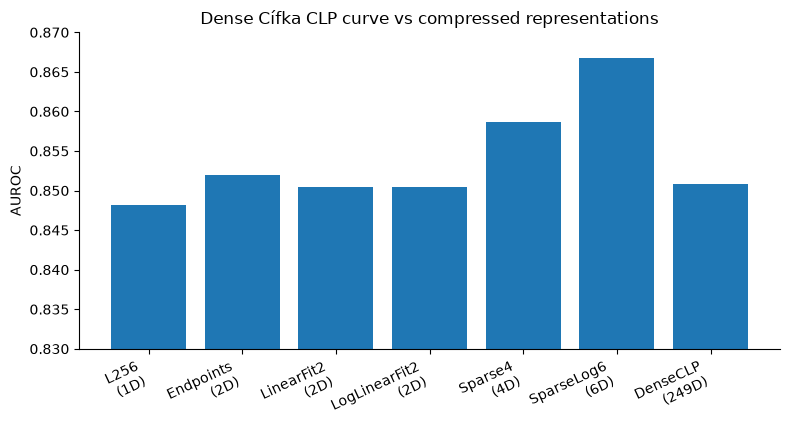

In [21]:
plot_order = [
    "L256",
    "Endpoints",
    "LinearFit2",
    "LogLinearFit2",
    "Sparse4",
    "SparseLog6",
    "DenseCLP",
]

dims = {m: len(FEATURE_SETS[m]) for m in plot_order}
aucs = outer.groupby("method")["auroc"].mean()

fig, ax = plt.subplots(figsize=(8.0, 4.5))
x = np.arange(len(plot_order))
ax.bar(x, [aucs[m] for m in plot_order])

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{m}\n({dims[m]}D)" for m in plot_order],
    rotation=25,
    ha="right",
)
ax.set_ylabel("AUROC")
ax.set_title("Dense Cífka CLP curve vs compressed representations")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.ylim(0.83,0.87)

fig.tight_layout()
fig.savefig(
    FIGURES / "cifka_dense_clp_compression.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "cifka_dense_clp_compression.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


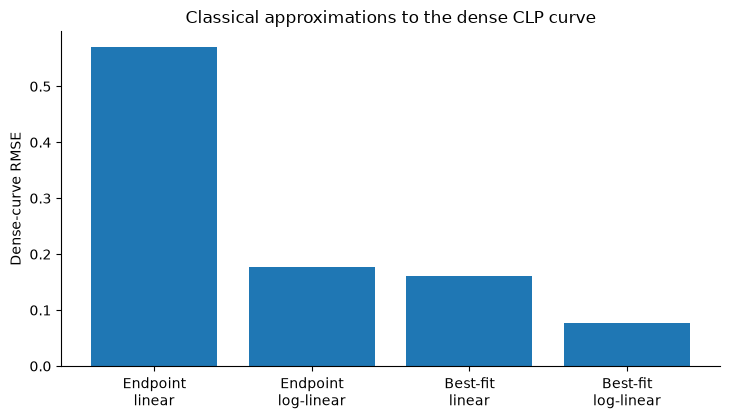

In [19]:
recon_means = dense_work[RECON_COLS].mean()

fig, ax = plt.subplots(figsize=(7.4, 4.3))
x = np.arange(len(RECON_COLS))
ax.bar(x, [recon_means[c] for c in RECON_COLS])

ax.set_xticks(x)
ax.set_xticklabels([
    "Endpoint\nlinear",
    "Endpoint\nlog-linear",
    "Best-fit\nlinear",
    "Best-fit\nlog-linear",
])
ax.set_ylabel("Dense-curve RMSE")
ax.set_title("Classical approximations to the dense CLP curve")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURES / "cifka_dense_clp_reconstruction.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "cifka_dense_clp_reconstruction.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# Interpretation checklist

Do **not** collapse reconstruction and attribution into the same claim.

### If reconstruction is excellent and attribution is preserved

Then the dense CLP response itself is approximately low-dimensional in this setting.

### If reconstruction is imperfect but attribution is preserved

Then the more interesting result is:

> The dense context-response curve contains shape variation, but little of that
> variation contributes generator-discriminative information beyond long-context
> predictive loss.

### Strong one-number compression criterion

The strongest result would be

\[
L_{256}\approx \mathrm{DenseCLP}
\]

under:

- nested regularization,
- matched source-group splits,
- and held-out-domain transfer.

Any retained-performance percentage refers only to **above-chance downstream
AUROC**, not mutual information or universal capability.


In [20]:
def fs(x):
    return f"{x:+.6f}"

print("ACTIVE TOOLKIT PATH")
print(
    "official run_probing"
    if OFFICIAL_XENT_OK
    else "compatibility adapter using released toolkit primitives"
)

print("\nEQUIVALENCE AUDIT")
if len(audit):
    print("mean abs error:", audit["abs_error"].mean())
    print("max abs error:", audit["abs_error"].max())

print("\nMEAN OUTER-SPLIT AUROC")
display(
    outer.groupby("method")["auroc"]
    .mean()
    .sort_values(ascending=False)
)

print("\nHEADLINE DELTAS")
for a,b in [
    ("Endpoints","L256"),
    ("DenseCLP","L256"),
    ("DenseCLP","Endpoints"),
    ("DenseCLP","LogLinearFit2"),
]:
    r = delta_summary[
        (delta_summary["comparison"] == f"{a} vs {b}")
        & (delta_summary["metric"] == "auroc")
    ].iloc[0]

    print(
        f"{a} - {b}",
        "| mean", fs(r.mean_delta),
        "| median", fs(r.median_delta),
        "| IQR", f"[{fs(r.q25)}, {fs(r.q75)}]",
        "| positive", f"{int(r.positive)}/{int(r.n)}",
    )

print("\nRETAINED PERFORMANCE")
display(retention)

print("\nRECONSTRUCTION")
display(dense_work[RECON_COLS].agg(["mean","median"]))

print("\nHELD-OUT DOMAIN")
display(
    transfer.pivot(
        index="heldout_domain_label",
        columns="method",
        values="auroc",
    )
)


ACTIVE TOOLKIT PATH
compatibility adapter using released toolkit primitives

EQUIVALENCE AUDIT
mean abs error: 0.0045163631439208984
max abs error: 0.01953125

MEAN OUTER-SPLIT AUROC


method
SparseLog6       0.866722
Sparse4          0.858722
Endpoints        0.852000
DenseCLP         0.850889
LinearFit2       0.850500
LogLinearFit2    0.850389
L256             0.848167
Name: auroc, dtype: float64


HEADLINE DELTAS
Endpoints - L256 | mean +0.003833 | median +0.003333 | IQR [-0.005833, +0.010556] | positive 12/20
DenseCLP - L256 | mean +0.002722 | median +0.003333 | IQR [-0.010000, +0.012222] | positive 11/20
DenseCLP - Endpoints | mean -0.001111 | median +0.007778 | IQR [-0.021944, +0.020000] | positive 11/20
DenseCLP - LogLinearFit2 | mean +0.000500 | median +0.001111 | IQR [-0.009167, +0.010556] | positive 10/20

RETAINED PERFORMANCE


,method,mean_auroc,absolute_gap_to_dense,above_chance_retained_fraction
0,L256,0.848167,0.002722,0.992242
1,Endpoints,0.852000,-0.001111,1.003167
2,Sparse4,0.858722,-0.007833,1.022324
3,SparseLog6,0.866722,-0.015833,1.045123
4,LinearFit2,0.850500,0.000389,0.998892
5,LogLinearFit2,0.850389,0.000500,0.998575



RECONSTRUCTION


,rmse_endpoint_linear,rmse_endpoint_log,rmse_fit_linear,rmse_fit_log
mean,0.569837,0.176162,0.160556,0.077823
median,0.555737,0.165197,0.155728,0.071460



HELD-OUT DOMAIN


method,DenseCLP,Endpoints,L256,LinearFit2,LogLinearFit2,Sparse4,SparseLog6
heldout_domain_label,,,,,,,
Essay,0.883270,0.877127,0.905009,0.897921,0.893667,0.893195,0.915406
Reuters,0.889629,0.925031,0.922949,0.917534,0.911703,0.890462,0.904207
Wikipedia,0.877739,0.851980,0.871972,0.876970,0.878893,0.865052,0.857747
